Tugas - Exact vs Annoy vs HNSW vs FAISS IVF pada 10.000 vektor 128D.

Dijalankan lokal (Windows 11). Google Colab & PyDroid3 tidak tersedia di sesi ini,
jadi perbandingan platform hanya bisa dilaporkan untuk mesin lokal.
Annoy/hnswlib tidak bisa di-build (tidak ada MSVC) -> padanan faiss:
IndexIVFFlat untuk Annoy, IndexHNSWFlat untuk HNSW.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("tugas_benchmark.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-ann-approximate-nearest-neighbors\tugas


In [2]:
from pathlib import Path
import csv
import os
import platform
import time

import numpy as np
import faiss
import matplotlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

OUT = Path(__file__).parent / "output"
OUT.mkdir(exist_ok=True)
N, D, K = 10_000, 128, 10

=== Ringkasan 10000 vektor 128D, k=10 (detik) ===
metode                        build    query  recall
Exact NN (sklearn brute)     0.0000   0.5571   1.000
Annoy -> faiss IVF           0.0953   0.1076   0.414
HNSW -> faiss HNSW           0.8661   1.2060   0.986
FAISS IVF                    0.1060   0.1542   0.414

Speedup query vs exact: IVF 5.2x, HNSW 0.5x
Top-5 index query pertama: exact [   0 9539 1112 4089 6177], IVF [   0 9539 1112 6177 9516], HNSW [   0 9539 1112 4089 6177]

Mesin: Windows 10, CPU 8 logical core, Python 3.10.6, faiss 1.15.1


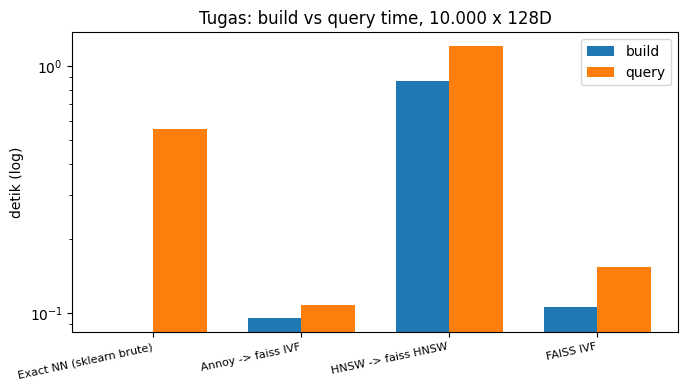

In [3]:
def recall(pred, gt):
    return float(np.mean([len(set(p) & set(g)) / K for p, g in zip(pred, gt)]))


rng = np.random.default_rng(42)
X = StandardScaler().fit_transform(rng.random((N, D), dtype=np.float32)).astype(np.float32)
Q = X

t0 = time.perf_counter()
nn = NearestNeighbors(n_neighbors=K, algorithm="brute", metric="euclidean").fit(X)
D_e, I_e = nn.kneighbors(Q)
t_exact = time.perf_counter() - t0

t0 = time.perf_counter()
ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(D), D, 100, faiss.METRIC_L2)
ivf.train(X)
ivf.add(X)
b_ivf = time.perf_counter() - t0
ivf.nprobe = 10
t0 = time.perf_counter()
_, I_ivf = ivf.search(Q, K)
t_ivf = time.perf_counter() - t0

t0 = time.perf_counter()
hn = faiss.IndexHNSWFlat(D, 16)
hn.hnsw.efConstruction = 200
hn.add(X)
b_hn = time.perf_counter() - t0
hn.hnsw.efSearch = 200
t0 = time.perf_counter()
_, I_hn = hn.search(Q, K)
t_hn = time.perf_counter() - t0

t0 = time.perf_counter()
q = faiss.IndexFlatL2(D)
ivf2 = faiss.IndexIVFFlat(q, D, 100, faiss.METRIC_L2)
ivf2.train(X)
ivf2.add(X)
b_f = time.perf_counter() - t0
ivf2.nprobe = 10
t0 = time.perf_counter()
_, I_f = ivf2.search(Q, K)
t_f = time.perf_counter() - t0

rows = [["Exact NN (sklearn brute)", 0.0, round(t_exact, 4), 1.0],
        ["Annoy -> faiss IVF", round(b_ivf, 4), round(t_ivf, 4), round(recall(I_ivf, I_e), 3)],
        ["HNSW -> faiss HNSW", round(b_hn, 4), round(t_hn, 4), round(recall(I_hn, I_e), 3)],
        ["FAISS IVF", round(b_f, 4), round(t_f, 4), round(recall(I_f, I_e), 3)]]

print(f"=== Ringkasan {N} vektor {D}D, k={K} (detik) ===")
print(f"{'metode':26s} {'build':>8s} {'query':>8s} {'recall':>7s}")
for name, b, t, r in rows:
    print(f"{name:26s} {b:8.4f} {t:8.4f} {r:7.3f}")
print(f"\nSpeedup query vs exact: IVF {t_exact/t_ivf:.1f}x, HNSW {t_exact/t_hn:.1f}x")
print(f"Top-5 index query pertama: exact {I_e[0][:5]}, IVF {I_ivf[0][:5]}, HNSW {I_hn[0][:5]}")
print(f"\nMesin: {platform.system()} {platform.release()}, CPU {os.cpu_count()} logical core, "
      f"Python {platform.python_version()}, faiss {faiss.__version__}")

with open(OUT / "hasil_tugas.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["metode", "build_s", "query_s", "recall@10"])
    w.writerows(rows)

fig, ax = plt.subplots(figsize=(7, 4))
names = [r[0] for r in rows]
ax.bar(np.arange(4) - 0.18, [r[1] for r in rows], width=0.36, label="build")
ax.bar(np.arange(4) + 0.18, [r[2] for r in rows], width=0.36, label="query")
ax.set_xticks(range(4))
ax.set_xticklabels(names, rotation=12, ha="right", fontsize=8)
ax.set_yscale("log")
ax.set_ylabel("detik (log)")
ax.set_title("Tugas: build vs query time, 10.000 x 128D")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "tugas_timing.png", dpi=120)